# SECOM: exploration and charts

A short walk through the results. The analysis itself lives in the scripts in
`src/`; this notebook only reads their outputs and draws a few charts.

Run `python src/run_all.py` first so the output files exist.

In [1]:
import sys
sys.path.insert(0, "../src")  # so we can import the project's scripts

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Image

import config
from spc_rules import check_rules, imr_limits

BLUE = "#2a78d6"
GREY = "#52514e"


def quiet_axes(ax):
    """Light grid, no box."""
    ax.grid(axis="y", color="#e1e0d9", linewidth=0.8)
    ax.set_axisbelow(True)
    for side in ("top", "right", "left"):
        ax.spines[side].set_visible(False)
    ax.tick_params(length=0)

## 1. The data

In [2]:
data = pd.read_csv(config.CLEAN_FILE, parse_dates=["timestamp"])
print("Runs:", len(data))
print("Features kept after cleaning:", data.shape[1] - len(config.ID_COLUMNS))
print("Time range:", data["timestamp"].min(), "to", data["timestamp"].max())
data["pass_fail"].value_counts()

Runs: 1567
Features kept after cleaning: 442
Time range: 2008-07-19 11:55:00 to 2008-10-17 06:07:00


pass_fail
Pass    1463
Fail     104
Name: count, dtype: int64

## 2. Missing values: why the threshold is 40%

Each feature's share of missing values, sorted from most to least missing.
There is a clear gap: no feature sits between 18% and 45%. Any threshold in
that gap drops the same 32 features.

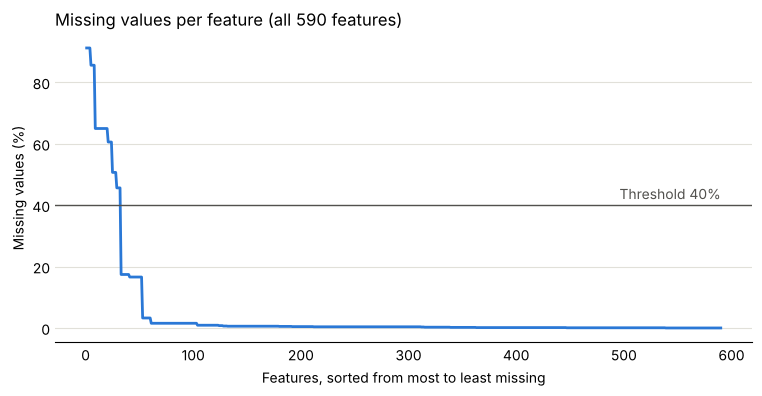

decision
keep                    442
drop: constant          116
drop: mostly missing     32
Name: count, dtype: int64

In [3]:
quality = pd.read_csv(config.FEATURE_QUALITY_FILE)
missing = quality["missing_fraction"].sort_values(ascending=False).to_numpy() * 100

fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(range(1, len(missing) + 1), missing, color=BLUE, linewidth=2)
ax.axhline(config.MAX_MISSING_FRACTION * 100, color=GREY, linewidth=1)
ax.text(len(missing), config.MAX_MISSING_FRACTION * 100 + 2, "Threshold 40%",
        ha="right", color=GREY)
ax.set_title("Missing values per feature (all 590 features)", loc="left")
ax.set_xlabel("Features, sorted from most to least missing")
ax.set_ylabel("Missing values (%)")
quiet_axes(ax)
plt.show()

quality["decision"].value_counts()

## 3. Fail rate over time

The fail rate is not constant. It is highest in the first 400 runs and mostly
lower afterwards, apart from one block around runs 1301 to 1400. This is why
the control charts use two stages, split at run 501.

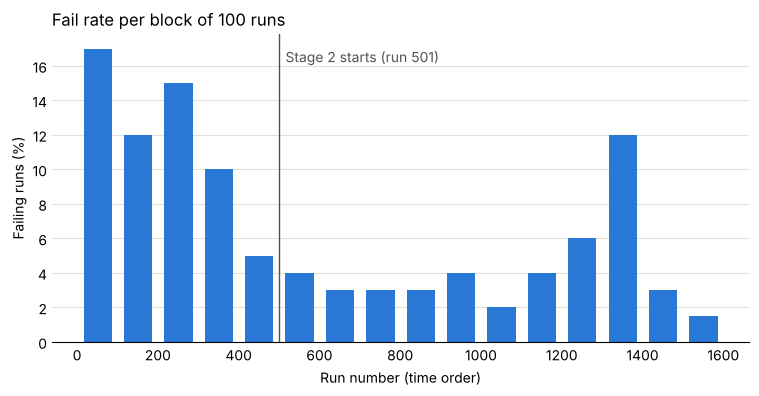

In [4]:
block = (data["run_id"] - 1) // 100          # 0 for runs 1-100, 1 for 101-200, ...
is_fail = data["pass_fail"] == "Fail"
fail_rate = is_fail.groupby(block).mean() * 100
block_start = fail_rate.index * 100 + 1      # first run of each block

fig, ax = plt.subplots(figsize=(9, 4))
ax.bar(block_start + 50, fail_rate, width=70, color=BLUE)
ax.axvline(config.STAGE_2_START, color=GREY, linewidth=1)
ax.text(config.STAGE_2_START + 15, fail_rate.max(), "Stage 2 starts (run 501)",
        va="top", color=GREY)
ax.set_title("Fail rate per block of 100 runs", loc="left")
ax.set_xlabel("Run number (time order)")
ax.set_ylabel("Failing runs (%)")
quiet_axes(ax)
plt.show()

## 4. Feature ranking: all runs versus inside each stage

`prob_fail_higher` is the chance that a random failing run reads higher than a
random passing run (0.5 means no difference). `p_adjusted` is the p-value after
the Benjamini-Hochberg correction.

Over all runs the top 10 are all significant. Inside each stage, only the
group f477 / f205 / f341 stays below 0.05, and only in stage 1.

In [5]:
by_stage = pd.read_csv(config.STAGE_RANKING_FILE)
by_stage.round(3)

,feature,rank_all,prob_fail_higher_all,p_adjusted_all,rank_stage1,prob_fail_higher_stage1,p_adjusted_stage1,rank_stage2,prob_fail_higher_stage2,p_adjusted_stage2
0,f059,1,0.692,0.000,6,0.622,0.164,23,0.616,0.158
1,f103,2,0.668,0.000,69,0.566,0.613,42,0.596,0.298
2,f510,3,0.636,0.001,70,0.566,0.613,39,0.597,0.298
3,f477,4,0.621,0.004,1,0.652,0.035,187,0.543,0.768
4,f205,5,0.619,0.004,2,0.651,0.035,208,0.539,0.803
5,f129,6,0.619,0.004,175,0.538,0.812,20,0.621,0.130
6,f028,7,0.383,0.004,316,0.484,0.958,77,0.426,0.531
7,f033,8,0.611,0.008,61,0.570,0.588,45,0.592,0.359
8,f341,9,0.610,0.008,3,0.647,0.035,284,0.526,0.871
9,f316,10,0.391,0.008,75,0.436,0.619,78,0.426,0.531


## 5. A control chart

The I-MR chart for the top-ranked feature. The limits step at run 501 because
each stage has its own limits. Charts for the other features are in
`reports/figures/`.

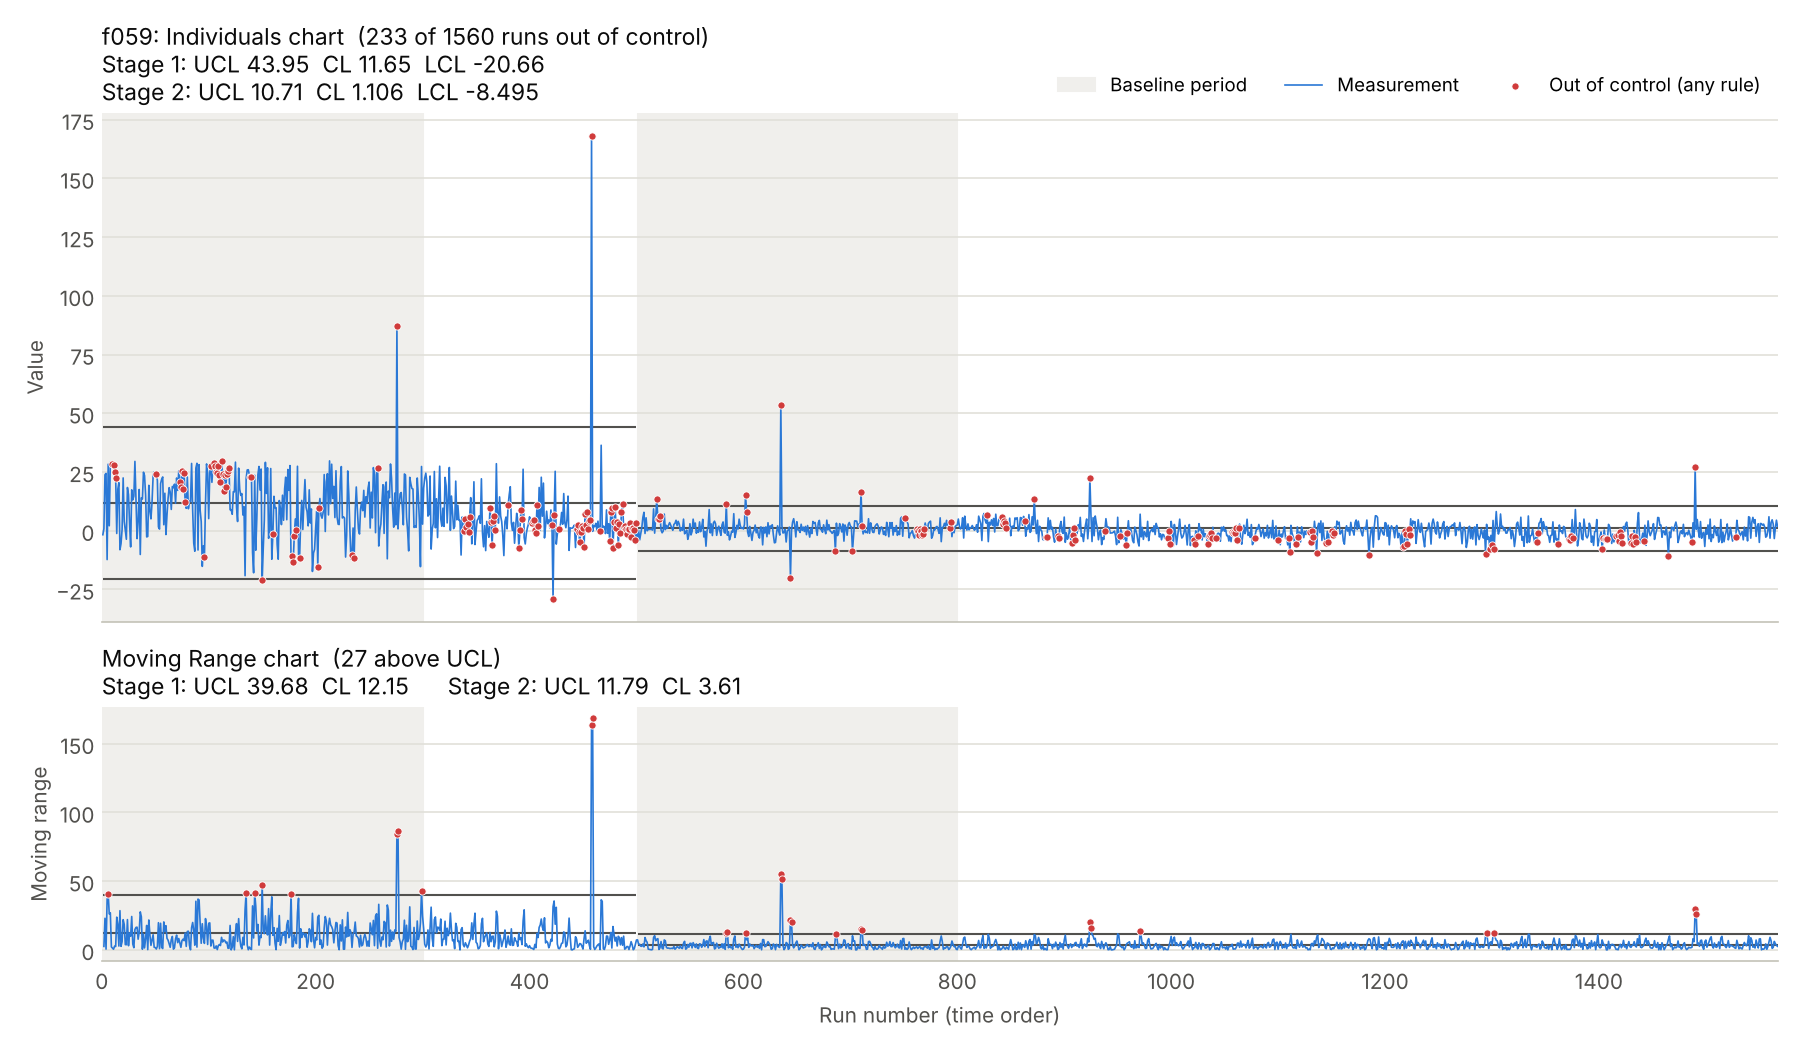

In [6]:
Image(filename=str(config.FIGURES_DIR / "imr_f059.png"), width=900)

## 6. What would a stable process look like?

To judge the out-of-control rates, we need a reference. Here we simulate a
perfectly stable process (random noise around a fixed mean), set limits from
its first 300 runs, and count how many later runs break a rule. We repeat
this 200 times.

In [7]:
rng = np.random.default_rng(0)   # fixed seed, so the result is repeatable
flagged_share = []
for _ in range(200):
    values = rng.normal(size=1067)                 # same length as stage 2
    limits = imr_limits(values[:config.BASELINE_RUNS])
    rules = check_rules(values, limits["center"], limits["sigma"])
    after_baseline = rules.any(axis=1).to_numpy()[config.BASELINE_RUNS:]
    flagged_share.append(after_baseline.mean())

print(f"Stable process, runs flagged after the baseline: "
      f"typically {np.median(flagged_share):.1%}, "
      f"rarely above {np.quantile(flagged_share, 0.95):.1%}")

limits_table = pd.read_csv(config.CONTROL_LIMITS_FILE)
limits_table[["feature", "stage", "ooc_rate_after_baseline"]].round(3)

Stable process, runs flagged after the baseline: typically 1.6%, rarely above 2.9%


,feature,stage,ooc_rate_after_baseline
0,f059,1,0.350
1,f059,2,0.126
2,f103,1,0.685
3,f103,2,0.246
4,f510,1,0.430
5,f510,2,0.239
6,f477,1,0.045
7,f477,2,0.507
8,f129,1,0.322
9,f129,2,0.648


The five charted features are flagged far more often than a stable process
would be, in both stages. None of them is in statistical control.

## 7. Capability against assumed spec limits

**The spec limits are an assumption** (passing-run mean plus and minus 3
sigma), because SECOM publishes none. Read the indices as a comparison
between features and stages, not as real capability.

In [8]:
capability = pd.read_csv(config.CAPABILITY_FILE)
capability[["feature", "stage", "lsl_assumed", "usl_assumed", "mean",
            "cp", "cpk", "pp", "ppk"]].round(2)

,feature,stage,lsl_assumed,usl_assumed,mean,cp,cpk,pp,ppk
0,f059,1,-25.38,30.50,9.12,0.93,0.71,0.67,0.51
1,f059,2,-25.38,30.50,0.05,2.90,2.64,2.36,2.15
2,f103,1,-0.02,-0.00,-0.01,1.57,1.16,1.04,0.78
3,f103,2,-0.02,-0.00,-0.01,1.45,1.31,1.16,1.04
4,f510,1,-52.87,161.75,74.35,1.02,0.83,0.73,0.59
5,f510,2,-52.87,161.75,47.04,1.91,1.78,1.33,1.24
6,f477,1,-22.56,34.77,7.30,2.32,2.23,0.63,0.60
7,f477,2,-22.56,34.77,5.77,4.09,4.05,1.47,1.45
8,f205,1,-24.99,42.76,10.40,2.08,1.98,0.65,0.62
9,f205,2,-24.99,42.76,8.42,3.44,3.39,1.54,1.52
